# Calculus with Vulkan Profiles

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.utils import fs_utils
from src.vulkan_math_data import (
    attach_catalog_and_benchmarks,
    feature_matrix,
    load_vulkan_feature_frame,
)

project_root, data_dir = fs_utils.get_data_dir()

sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_columns", 12)
project_root, data_dir

(PosixPath('/opt/pc-hardware-analysis'),
 PosixPath('/opt/pc-hardware-analysis/data'))

In [9]:
vulkan_frame = load_vulkan_feature_frame(data_dir / "vulkan-profiles")
joined_frame, diagnostics = attach_catalog_and_benchmarks(vulkan_frame)
model_frame = joined_frame.copy()
model_frame["target_score"] = model_frame["benchmark"]
target_name = "benchmark"

if model_frame["target_score"].notna().sum() < 2:
    target_name = "surrogate_capability_score"
    model_frame["target_score"] = (
        model_frame["agg__feature_true_count"]
        + 0.5 * model_frame["agg__descriptor_feature_count"]
        + 0.5 * model_frame["agg__raytracing_feature_count"]
    )

display(model_frame[["report_id", "normalized_gpu_name", "benchmark", "target_score"]])
print("Target used for this run:", target_name)
print("Benchmark matches:", diagnostics["benchmark_matches"])

,report_id,normalized_gpu_name,benchmark,target_score
0,10934,rtx 3090,87.4,87.4
1,10993,rtx 3080,78.9,78.9
2,10993,rtx 3080,51.8,51.8
3,11121,rtx 3080,78.9,78.9
4,11121,rtx 3080,51.8,51.8
...,...,...,...,...
542,49144,arc a770,46.1,46.1
543,49180,rtx 4080,122.0,122.0
544,49180,rtx 4080,77.1,77.1
545,49185,rtx 5090,183.0,183.0


Target used for this run: benchmark
Benchmark matches: 507


In [10]:
X, matrix_columns = feature_matrix(model_frame)
y = model_frame["target_score"].fillna(model_frame["target_score"].median())

ridge_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("ridge", Ridge(alpha=1.0)),
    ]
)
ridge_model.fit(X, y)
ridge_pred = ridge_model.predict(X)

mlp_model = Pipeline(
    [
        ("scale", StandardScaler()),
        (
            "mlp",
            MLPRegressor(
                hidden_layer_sizes=(8,),
                activation="relu",
                random_state=7,
                max_iter=1500,
            ),
        ),
    ]
)
mlp_model.fit(X, y)
mlp_pred = mlp_model.predict(X)

results = pd.DataFrame(
    {
        "model": ["ridge", "mlp"],
        "mae": [mean_absolute_error(y, ridge_pred), mean_absolute_error(y, mlp_pred)],
        "r2": [r2_score(y, ridge_pred), r2_score(y, mlp_pred)],
    }
)
display(results)

comparison = model_frame[["report_id", "normalized_gpu_name"]].copy()
comparison["target_score"] = y
comparison["ridge_prediction"] = ridge_pred
comparison["mlp_prediction"] = mlp_pred
display(comparison)

/opt/pc-hardware-analysis/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,mae,r2
0,ridge,2.719120,0.960124
1,mlp,2.479708,0.980097


,report_id,normalized_gpu_name,target_score,ridge_prediction,mlp_prediction
0,10934,rtx 3090,87.4,87.364023,87.596534
1,10993,rtx 3080,78.9,77.358302,73.876183
2,10993,rtx 3080,51.8,54.214523,58.180994
3,11121,rtx 3080,78.9,77.768429,71.550929
4,11121,rtx 3080,51.8,54.624650,55.855741
...,...,...,...,...,...
542,49144,arc a770,46.1,76.656390,60.241986
543,49180,rtx 4080,122.0,119.151205,121.603492
544,49180,rtx 4080,77.1,80.805976,82.159161
545,49185,rtx 5090,183.0,185.239870,186.978546


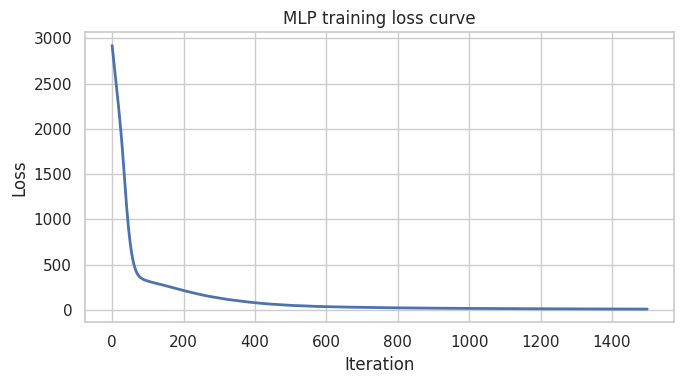

In [11]:
loss_curve = mlp_model.named_steps["mlp"].loss_curve_
plt.figure(figsize=(7, 4))
plt.plot(loss_curve, linewidth=2)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

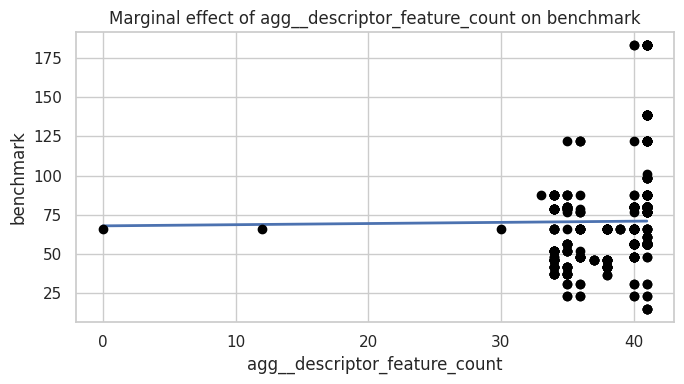

,feature_value,estimated_derivative
0,0.000000,0.074205
1,1.708333,0.074205
2,3.416667,0.074205
3,5.125000,0.074205
4,6.833333,0.074205


In [13]:
preferred_features = [
    "agg__extension_count",
    "agg__descriptor_feature_count",
    "agg__raytracing_feature_count",
    "agg__feature_true_count",
]
analysis_feature = next(
    (
        feature
        for feature in preferred_features
        if feature in X.columns and X[feature].nunique() > 1
    ),
    None,
)

if analysis_feature is None:
    print(
        "No non-constant engineered aggregate is available for marginal-effect analysis yet."
    )
else:
    feature_grid = np.linspace(X[analysis_feature].min(), X[analysis_feature].max(), 25)
    reference = pd.concat(
        [X.mean().to_frame().T] * len(feature_grid), ignore_index=True
    )
    reference[analysis_feature] = feature_grid
    ridge_grid_prediction = ridge_model.predict(reference)

    plt.figure(figsize=(7, 4))
    plt.plot(feature_grid, ridge_grid_prediction, linewidth=2)
    plt.scatter(X[analysis_feature], y, color="black", zorder=3)
    plt.title(f"Marginal effect of {analysis_feature} on {target_name}")
    plt.xlabel(analysis_feature)
    plt.ylabel(target_name)
    plt.tight_layout()
    plt.show()

    gradient = np.gradient(ridge_grid_prediction, feature_grid)
    marginal_frame = pd.DataFrame(
        {"feature_value": feature_grid, "estimated_derivative": gradient}
    )
    display(marginal_frame.head())